# MoE comparisons: four models trained end-to-end

**What it does.** Classifies 64x64 images into 200 classes with four models. All four use the **same backbone architecture** (a small ResNet), but each model builds its **own new copy** and trains backbone and head **together from scratch**, with the same settings (no augmentation, same epochs, learning rate and weight decay). Only the head differs:

| model | idea |
|---|---|
| **CNN** | baseline: one ordinary dense layer |
| **MoE** | several small expert networks and a *gate* that decides how much each expert counts for an image |
| **pMoE** | each expert looks only at the few image patches its router picks |
| **MGE** | one expert on each depth of the backbone (shallow, middle, deep); their answers are averaged |

Because the backbone learns together with each head, the routing of MoE / pMoE / MGE can shape the features. (On a frozen, pretrained backbone every head ended up at the backbone's own score, so that comparison said nothing about the heads.)

**How to run**
1. Open the notebook on a machine with a GPU if you can (RunPod, Colab or local, see the README).
2. Run the cells from top to bottom. The cell you may want to edit is **Settings**.
3. Each model writes a log to `MoE_comparisons/history_logs/` and its weights (backbone + head) to `MoE_comparisons/models/` as soon as it is trained. The names end in `RUN_TAG`: change it to keep older runs instead of overwriting them. To retrain a single model, run only its cell.
4. The last code cell prints a table with the final train and validation scores of all four models.
5. To look at results again **without training**, set `USE_SAVED = True` (first code cell) and run everything: weights and logs are loaded from disk (or from GitHub on a new pod).

Only the **validation** split is used here. The test split is not touched.

In [6]:
!nvidia-smi #--query-compute-apps=pid,process_name,used_memory --format=csv

Fri Nov 20 16:37:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.14              Driver Version: 550.54.14      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX A6000               Off |   00000000:41:00.0 Off |                  Off |
| 44%   70C    P2            140W /  300W |    1902MiB /  49140MiB |     43%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [56]:
USE_SAVED = False   # True: load the saved backbone, head weights and logs instead of training (analyse old runs)

import os, sys, subprocess
import warnings
warnings.filterwarnings('ignore')
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

REPO_URL = 'https://github.com/durak-dev/ImageClassification.git'
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # Colab starts with an empty VM: clone the repo (code AND data live in it).
    # On later runs the folder already exists, so just pull the newest commits.
    ROOT = '/content/ImageClassification'
    if not os.path.exists(ROOT):
        subprocess.run(['git', 'clone', REPO_URL, ROOT], check=True)
    else:
        # fetch + hard reset instead of `pull`: always lands on the newest origin commit, even if the VM copy diverged
        subprocess.run(['git', '-C', ROOT, 'fetch', 'origin'], check=True)
        subprocess.run(['git', '-C', ROOT, 'reset', '--hard', '@{u}'], check=True)
else:
    # Local: the notebook sits in the project root, but also work if it was
    # started from a subfolder.
    cwd = os.path.abspath(os.getcwd())
    ROOT = cwd if os.path.isdir(os.path.join(cwd, 'utils')) else os.path.dirname(cwd)

os.chdir(ROOT)
sys.path.insert(0, ROOT)          # so `import utils.funcs` finds OUR utils folder

DATA_DIR = os.path.join(ROOT, 'data')
ORIG_DIR = os.path.join(DATA_DIR, 'original')            # raw images/ + labels/ (placed manually, never modified)
MANIFEST_PATH = os.path.join(DATA_DIR, 'split_manifest.csv')   # which file belongs to which split
SEED = 42
NB_DIR = 'MoE_comparisons'   # this notebook's output folder (relative to the project root)
MODELS_DIR = f'{NB_DIR}/models'          # backbones and head weights
HISTORY_DIR = f'{NB_DIR}/history_logs'   # one CSV log per training run
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(HISTORY_DIR, exist_ok=True)
print('Running on:', 'Google Colab' if IN_COLAB else 'local machine')
print('Project root:', ROOT)

Running on: local machine
Project root: /home/20240644


In [57]:
# the kernel survives between runs: drop every cached utils module so the code git just pulled is what gets imported
for _m in [m for m in sys.modules if m == 'utils' or m.startswith('utils.')]:
    del sys.modules[_m]
from utils.funcs import *
from utils import config, github_sync, plotting, resnet
from utils.github_sync import save_csv, load_csv, push_files
from utils.MoE import *

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers
from sklearn.metrics import f1_score
tf.keras.mixed_precision.set_global_policy('mixed_float16')   # ~2x faster on the GPU

### Where the results go
Logs go to `MoE_comparisons/history_logs/`, backbones and model weights to `MoE_comparisons/models/` (this notebook's own output folder). A RunPod pod or Colab VM loses its disk when it ends, so the next cell offers two ways to keep them:
* **Push to GitHub:** paste a GitHub token into the box (hidden, kept in memory only). Everything is then committed to the `checkpoints` branch as soon as it is written, and a new pod downloads the saved backbone from there instead of training it again. Leave the box empty to skip.
* **Copy to your PC:** run `.\pull_results.ps1 -Ip <ip> -Port <port>` before you terminate the pod (see the README).

Running locally you can ignore this cell: everything stays in the project folder.

In [58]:
# Is the disk temporary? Colab VM, or a RunPod pod (pod_bootstrap.sh clones the repo into /workspace).
ON_POD = ROOT.startswith('/workspace/') or bool(os.environ.get('RUNPOD_POD_ID'))
REMOTE = IN_COLAB or ON_POD
if REMOTE:
    config.ensure_github()      # asks once for a GitHub token (hidden box, kept in memory only); empty = no upload
USE_GITHUB = REMOTE and config.github_ready()

if USE_GITHUB:
    _, repo, branch = config.github_settings()
    print(f'Results -> GitHub {repo}@{branch}: every log, backbone and weight file is committed when it is written')
elif ON_POD:
    print('Results stay on the pod. Copy them to your PC before terminating it:  .\\pull_results.ps1 -Ip <ip> -Port <port>')
else:
    print(f'Results -> local folders ({HISTORY_DIR}/, {MODELS_DIR}/)')

Results -> local folders (MoE_comparisons/history_logs/, MoE_comparisons/models/)


In [59]:
# Recreate data/{split}/ with the corrected images + labels if they are missing (fresh Colab VM).
# Needs split_manifest.csv, data/original/ and the two checkpoint files from the cloned repo.
if not all(os.path.exists(os.path.join(split_dir(DATA_DIR, s, 'labels'), CORRECTED_LABELS_FILE)) for s in SPLITS):
    materialize_splits(ORIG_DIR, DATA_DIR, pd.read_csv(MANIFEST_PATH))
    rebuild_corrected(pd.read_csv(os.path.join(ROOT, 'checkpoints', 'df_fixed.csv')), DATA_DIR,
                      labels_corrected=pd.read_csv(os.path.join(ROOT, 'checkpoints', 'labels_corrected.csv')))

In [11]:
dfs = {s: pd.read_csv(os.path.join(split_dir(DATA_DIR, s, "labels"), CORRECTED_LABELS_FILE)) for s in ["train", "val", "test"]}
classes = sorted(dfs["train"]["class_id"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

## Data
Images are resized to 64x64. **Only the training set is rebalanced** (classes with few images are repeated up to the median class size); validation and test stay as they are.

In [41]:
SIZE, BATCH, AUTOTUNE = 64, 256, tf.data.AUTOTUNE
CLASS_BALANCE = 'oversample'         # train set only: None | "oversample" | "undersample"  (see funcs.balance_frame)
CLASS_BALANCE_TARGET = 'median'  # images per class: None (max / min) | "min" | "median" | "max" | int

def load(path, y):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    img = tf.image.resize(img, (SIZE, SIZE))
    return tf.cast(tf.round(img), tf.uint8), y        # uint8: 4x smaller in the RAM cache below

def make_ds(split, shuffle):
    df = dfs[split]
    if split == "train" and CLASS_BALANCE:      # never resample val / test
        df = balance_frame(df, CLASS_BALANCE, CLASS_BALANCE_TARGET, seed=SEED)
        n = df["class_id"].value_counts()
        print(f"train balanced ({CLASS_BALANCE}): {len(df)} images, {n.min()}-{n.max()} per class")
    paths = (f"{DATA_DIR}/{split}/images_corrected/" + df["filename"].astype(str)).values
    labels = df["class_id"].map(class_to_idx)
    assert labels.notna().all(), f"{split} has labels not present in train"
    ds = tf.data.Dataset.from_tensor_slices((paths, labels.values.astype("int32")))
    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()   # decode + resize ONCE; later epochs read from RAM
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED)                  # after cache(), so the order still changes every epoch
    ds = ds.batch(BATCH).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train, val, test = make_ds("train", True), make_ds("val", False), make_ds("test", False)
print(len(classes), "classes")
print(dfs["train"]["filename"].iloc[0], os.path.exists(f"{DATA_DIR}/train/images_corrected/" + str(dfs["train"]["filename"].iloc[0])))
for x, y in train.take(1):
    print(x.shape, x.dtype, float(tf.reduce_min(x)), float(tf.reduce_max(x)))

train balanced (oversample): 38600 images, 193-193 per class
200 classes
image_000002.JPEG True
(256, 64, 64, 3) <dtype: 'float32'> 0.0 255.0


## Settings
Everything you might want to change is in the next cell. All four models are trained with exactly the same settings:

* **Backbone** - `blocks` is the number of residual blocks per stage, `drop` the dropout inside the backbone.
* **Training** - at most `EPOCHS` epochs, 2 epochs linear warmup to `LR`, then cosine decay to 0 at `EPOCHS`; AdamW with `WEIGHT_DECAY`. Training stops early when the validation loss has not improved for `PATIENCE` epochs (the best epoch's weights are kept). **No augmentation.**
* **Heads** - the settings of the individual models.

In [62]:
# ======== Settings ========

# --- backbone architecture (every model builds its own new copy and trains it together with its head)
BACKBONE = dict(
    blocks=(1, 2, 2, 1),   # residual blocks per stage; fewer blocks = faster epochs
    drop=0.3,              # dropout inside the backbone (after stages 2 and 3)
)

# --- training: the same for all four models
EPOCHS = 20               # max epochs = length of the cosine schedule
PATIENCE = 5              # early stopping: epochs without a better val loss
LR = 0.005                 # PEAK learning rate (linear warmup, then cosine decay to 0)
WARMUP_EPOCHS = 2
WEIGHT_DECAY = 0.05       # AdamW, applied as lr * wd per step; not on bias / BN
AUG = None                # no augmentation
RUN_TAG = f'e2e_{EPOCHS}ep'   # end of every log / weights name: change it to keep older runs

# --- heads
FEATURE_DROP = 0.3        # CNN / MoE: dropout on the pooled s3 features
N_EXPERTS = 8             # MoE / pMoE: number of experts
BALANCE = 0.01            # MoE: weight of the load-balancing loss
L_PATCHES = 16             # pMoE: patches each expert keeps (at most 64)
DIVERSITY_WEIGHT = 0.08   # MGE: weight of the diversity penalty

STEPS = int(train.cardinality())   # batches per epoch
LR_SCHEDULE = tf.keras.optimizers.schedules.CosineDecay(0.0, decay_steps=(EPOCHS - WARMUP_EPOCHS) * STEPS,
                                                        warmup_target=LR, warmup_steps=WARMUP_EPOCHS * STEPS)


def run(model, name, epochs=EPOCHS, gate=False, initial_epoch=0, save=True):
    """Train `model` and return its History; with USE_SAVED, load its saved weights and log instead.
    Log: <HISTORY_DIR>/<name>.csv, weights (best epoch): <MODELS_DIR>/<name>.weights.h5, both pushed to GitHub if USE_GITHUB.
    initial_epoch > 0 continues an earlier run: its epochs are appended to the same log."""
    log_path, weights_path = f'{HISTORY_DIR}/{name}.csv', f'{MODELS_DIR}/{name}.weights.h5'
    if USE_SAVED:
        for p in (log_path, weights_path):
            if not resnet.fetch_if_missing(p, USE_GITHUB):
                raise FileNotFoundError(f'{p} is missing: train this run first (USE_SAVED = False)')
        model.load_weights(weights_path)
        history = tf.keras.callbacks.History()
        history.history = pd.read_csv(log_path).to_dict('list')
    else:
        callbacks = ([GateMonitor(val)] if gate else []) + [       # before CSVLogger, so their values land in the log
            MacroF1(val),
            tf.keras.callbacks.CSVLogger(log_path, append=initial_epoch > 0),
            tf.keras.callbacks.EarlyStopping(patience=PATIENCE, restore_best_weights=True)]
        history = model.fit(train, validation_data=val, initial_epoch=initial_epoch, epochs=initial_epoch + epochs,
                            callbacks=callbacks)
        files = {log_path: log_path}
        if save:
            model.save_weights(weights_path)
            files[weights_path] = weights_path
        if USE_GITHUB:
            push_files(files, f'run: {name}')
    plot_history(history)
    return history

## The backbone
A ResNet written for 64x64 images (no early downsampling). Its code is the function `backbone` below, so you can change it right there (layers, widths; the number of blocks per stage is `BACKBONE['blocks']`). It has four stages; the outputs of stages 2, 3 and 4 (`s1`, `s2`, `s3`) are what the heads use:

```
image 64x64 -> stem -> stage 1 -> stage 2 (s1: 32x32x64) -> stage 3 (s2: 16x16x128) -> stage 4 (s3: 8x8x256)
```

| model | reads |
|---|---|
| CNN, MoE | `s3`, averaged to 256 numbers |
| pMoE | `s3` as 64 patches (the 8x8 grid) of 256 numbers |
| MGE | `s1`, `s2` and `s3` |

`fresh_backbone` builds a **new, trainable** copy for every model, so the four models start from the same architecture but never share weights.

In [60]:
# The backbone: edit it freely. It must return [s1, s2, s3] (shallow -> deep); the settings come from BACKBONE above.
def backbone(inp):
    """Conv layers only (no augmentation) -> [s1, s2, s3], shallow -> deep."""
    drop, (n1, n2, n3, n4) = BACKBONE['drop'], BACKBONE['blocks']
    x = layers.Rescaling(1 / 255)(inp)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)     # stem
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    # stage 1: 64 x 64 x 32, no downsampling
    for _ in range(n1):
        x = res_block(x, 32, downsample=False)

    # stage 2: 32 x 32 x 64
    x = res_block(x, 64)
    for _ in range(n2 - 1):
        x = res_block(x, 64, downsample=False)
    s1 = x                                        # MGE expert 0
    x = layers.SpatialDropout2D(drop)(x)

    # stage 3: 16 x 16 x 128
    x = res_block(x, 128)
    for _ in range(n3 - 1):
        x = res_block(x, 128, downsample=False)
    s2 = x                                        # MGE expert 1
    x = layers.SpatialDropout2D(drop)(x)

    # stage 4: 8 x 8 x 256
    x = res_block(x, 256)
    for _ in range(n4 - 1):
        x = res_block(x, 256, downsample=False)
    s3 = x                                        # MGE expert 2, pMoE, CNN / MoE (pooled)

    return [s1, s2, s3]


def fresh_backbone(inp, augmentation=None):
    """A NEW, trainable backbone for every model, trained together with its head: image -> [s1, s2, s3]."""
    x = augmentation(inp) if augmentation is not None else inp
    return backbone(x)

## 1. CNN (baseline)
```
backbone (s3) -> average over the 8x8 grid -> 256 numbers -> dropout -> Dense(N_EXPERTS x 128, ReLU) -> dropout -> Dense(200)
```
The hidden layer has as many units as all MoE experts together, so the MoE has no extra capacity compared with this baseline.

Epoch 1/20


I0000 00:00:1795197957.063611 3218847 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1763747__.150


150/151 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.0108 - loss: 5.2681

I0000 00:00:1795197970.952825 3218846 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1763747__.150


151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.0110 - loss: 5.2675  val macro-F1 0.0014
151/151 ━━━━━━━━━━━━━━━━━━━━ 27s 125ms/step - accuracy: 0.0110 - loss: 5.2675 - val_accuracy: 0.0122 - val_loss: 5.6075 - val_f1: 0.0014
Epoch 2/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.0233 - loss: 5.0785  val macro-F1 0.0043
151/151 ━━━━━━━━━━━━━━━━━━━━ 11s 71ms/step - accuracy: 0.0233 - loss: 5.0785 - val_accuracy: 0.0193 - val_loss: 5.3146 - val_f1: 0.0043
Epoch 3/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.0320 - loss: 4.9670  val macro-F1 0.0075
151/151 ━━━━━━━━━━━━━━━━━━━━ 11s 73ms/step - accuracy: 0.0320 - loss: 4.9670 - val_accuracy: 0.0218 - val_loss: 5.2538 - val_f1: 0.0075
Epoch 4/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.0412 - loss: 4.8558  val macro-F1 0.0251
151/151 ━━━━━━━━━━━━━━━━━━━━ 11s 72ms/step - accuracy: 0.0412 - loss: 4.8558 - val_accuracy: 0.0538 - val_loss: 4.8172 - val_f1: 0.0251
Epoch 5/20
151/151 ━━━━━━━━━━━━━━━

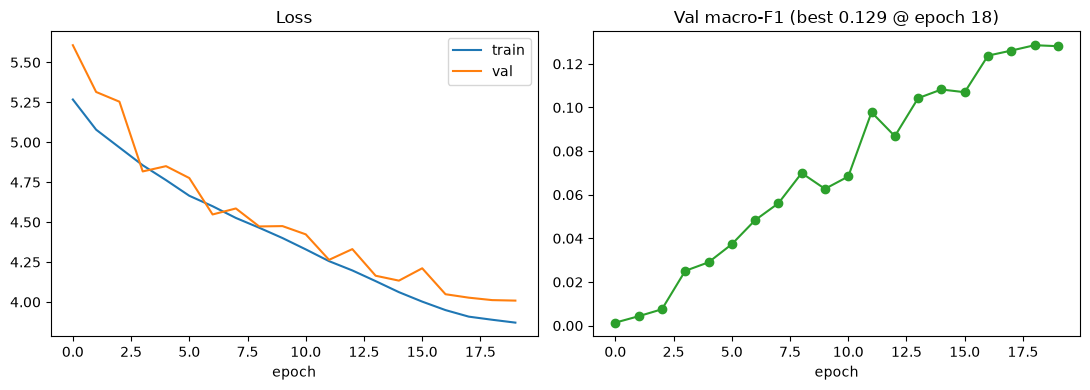

In [63]:
tf.keras.backend.clear_session()
cnn = build_cnn(SIZE, len(classes), fresh_backbone, n_experts=N_EXPERTS, augmentation=AUG, drop=FEATURE_DROP,
                lr=LR_SCHEDULE, weight_decay=WEIGHT_DECAY)
hist_cnn = run(cnn, f'cnn_{RUN_TAG}')

## 2. MoE (soft mixture of experts)
```
256 numbers -> gate:      Dense(N_EXPERTS, softmax)                 -> one weight per expert (they sum to 1)
            -> expert i:  Dense(128, ReLU) -> dropout -> Dense(200) -> class scores
output = sum over experts of  gate weight x expert scores
```
* Every expert runs on every image; the gate only decides how much each one counts.
* A **load-balancing loss** (weight `BALANCE`) rewards using all experts equally. Without it the gate tends to rely on one or two experts.
* While training, the notebook prints the average gate weight per expert (`usage`) and how often each expert has the largest weight (`wins`).

Epoch 1/20


I0000 00:00:1795198196.057533 3218847 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1810645__.208


150/151 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.0080 - loss: 5.3034

I0000 00:00:1795198213.298510 3218846 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1810645__.208


151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step - accuracy: 0.0081 - loss: 5.3030

I0000 00:00:1795198218.931530 3218846 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_reduce_slice_fusion', 180 bytes spill stores, 144 bytes spill loads

I0000 00:00:1795198219.597405 3218847 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1812410__.14
I0000 00:00:1795198221.800208 3218846 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1812410__.14


  usage [0.16 0.14 0.07 0.06 0.1  0.24 0.12 0.11]  wins [1054 1199  411    0   31 1227  824  374]


I0000 00:00:1795198224.750307 3218848 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1813947__.6
I0000 00:00:1795198226.895336 3218847 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1814742__.6


  val macro-F1 0.0021
151/151 ━━━━━━━━━━━━━━━━━━━━ 39s 172ms/step - accuracy: 0.0081 - loss: 5.3030 - val_accuracy: 0.0162 - val_loss: 5.2453 - gate_usage_0: 0.1571 - gate_usage_1: 0.1389 - gate_usage_2: 0.0700 - gate_usage_3: 0.0597 - gate_usage_4: 0.0990 - gate_usage_5: 0.2376 - gate_usage_6: 0.1239 - gate_usage_7: 0.1138 - gate_balance: 0.9598 - val_f1: 0.0021
Epoch 2/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step - accuracy: 0.0218 - loss: 5.1103  usage [0.15 0.14 0.12 0.05 0.15 0.2  0.02 0.17]  wins [ 903  963  757   19  414 1145   10  909]
  val macro-F1 0.0073
151/151 ━━━━━━━━━━━━━━━━━━━━ 11s 74ms/step - accuracy: 0.0218 - loss: 5.1103 - val_accuracy: 0.0243 - val_loss: 5.3316 - gate_usage_0: 0.1450 - gate_usage_1: 0.1449 - gate_usage_2: 0.1213 - gate_usage_3: 0.0471 - gate_usage_4: 0.1487 - gate_usage_5: 0.2001 - gate_usage_6: 0.0239 - gate_usage_7: 0.1689 - gate_balance: 0.9401 - val_f1: 0.0073
Epoch 3/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.0306 - loss: 4.962

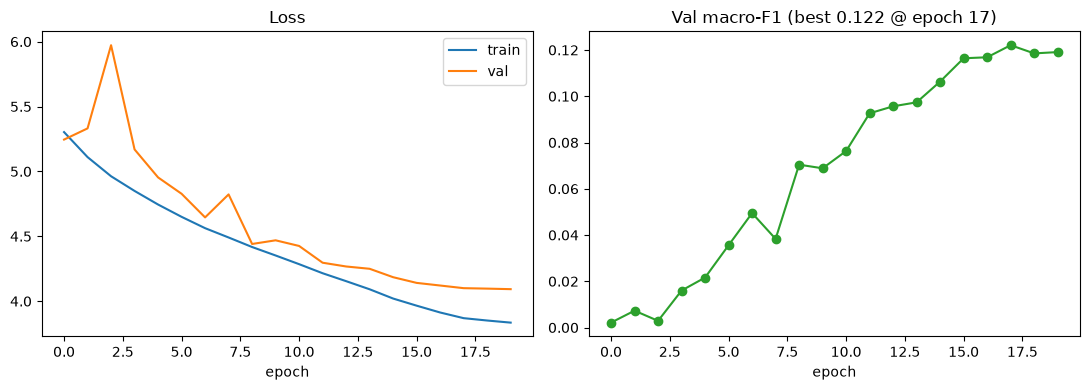

In [64]:
tf.keras.backend.clear_session()
moe_model = build_moe(SIZE, len(classes), fresh_backbone, n_experts=N_EXPERTS, balance=BALANCE, augmentation=AUG,
                      drop=FEATURE_DROP, lr=LR_SCHEDULE, weight_decay=WEIGHT_DECAY)
hist_moe = run(moe_model, f'moe_{RUN_TAG}', gate=True)

The plot shows how the gate spreads the images over the experts: left, the average weight of each expert per epoch; right, how even that spread is (1 = all experts equal, 0 = a single expert).

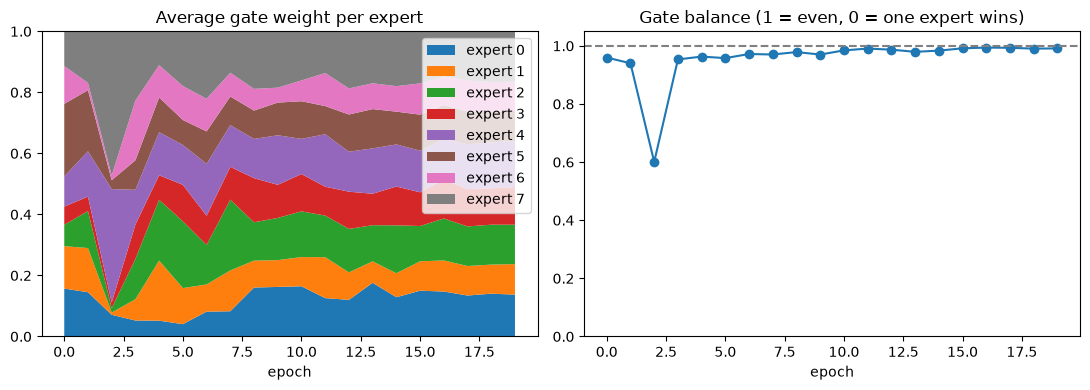

In [65]:
# the gate columns are written into the log by GateMonitor (so this also works with USE_SAVED)
h = hist_moe.history
cols = sorted((c for c in h if c.startswith('gate_usage_')), key=lambda c: int(c.rsplit('_', 1)[1]))
if not cols:
    print('this log has no gate columns (it was trained before GateMonitor wrote them): retrain the MoE to see the plot')
else:
    usage = np.array([h[c] for c in cols]).T          # (epochs, experts)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].stackplot(range(len(usage)), usage.T, labels=[f"expert {i}" for i in range(usage.shape[1])])
    ax[0].set(title="Average gate weight per expert", xlabel="epoch", ylim=(0, 1))
    ax[0].legend(loc="upper right")

    ax[1].plot(h['gate_balance'], marker="o")
    ax[1].axhline(1, ls="--", c="gray")
    ax[1].set(title="Gate balance (1 = even, 0 = one expert wins)", xlabel="epoch", ylim=(0, 1.05))
    plt.tight_layout(); plt.show()

## 3. pMoE (patch-level routing)
Adapted from *Patch-level Routing in Mixture-of-Experts* (Chowdhury et al., ICML 2023). The 8x8 feature map is treated as 64 patches.
```
for every expert:
    router:   scores all 64 patches and keeps the best L_PATCHES
    expert:   Dense(64, ReLU) -> dropout on each kept patch, weighted average of the patches, Dense(200) -> class scores
output = sum of the experts' scores
```
Each expert looks at only a part of the image, and nothing forces the experts to choose different parts. The two plots after training show **which patches** each expert picked and **how much two experts overlap**.

Epoch 1/20


I0000 00:00:1795198455.193943 3218845 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1864841__.240


150/151 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.0071 - loss: 5.4818

I0000 00:00:1795198472.677249 3218848 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1864841__.240


151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.0071 - loss: 5.4806  val macro-F1 0.0003
151/151 ━━━━━━━━━━━━━━━━━━━━ 40s 172ms/step - accuracy: 0.0071 - loss: 5.4806 - val_accuracy: 0.0064 - val_loss: 5.3019 - val_f1: 2.9884e-04
Epoch 2/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.0196 - loss: 5.1307  val macro-F1 0.0074
151/151 ━━━━━━━━━━━━━━━━━━━━ 11s 75ms/step - accuracy: 0.0196 - loss: 5.1307 - val_accuracy: 0.0187 - val_loss: 5.2866 - val_f1: 0.0074
Epoch 3/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.0323 - loss: 4.9818  val macro-F1 0.0170
151/151 ━━━━━━━━━━━━━━━━━━━━ 11s 74ms/step - accuracy: 0.0323 - loss: 4.9818 - val_accuracy: 0.0332 - val_loss: 5.0448 - val_f1: 0.0170
Epoch 4/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.0433 - loss: 4.8513  val macro-F1 0.0151
151/151 ━━━━━━━━━━━━━━━━━━━━ 11s 75ms/step - accuracy: 0.0433 - loss: 4.8513 - val_accuracy: 0.0316 - val_loss: 5.2118 - val_f1: 0.0151
Epoch 5/20
150/151 ━━━━━━━━━━

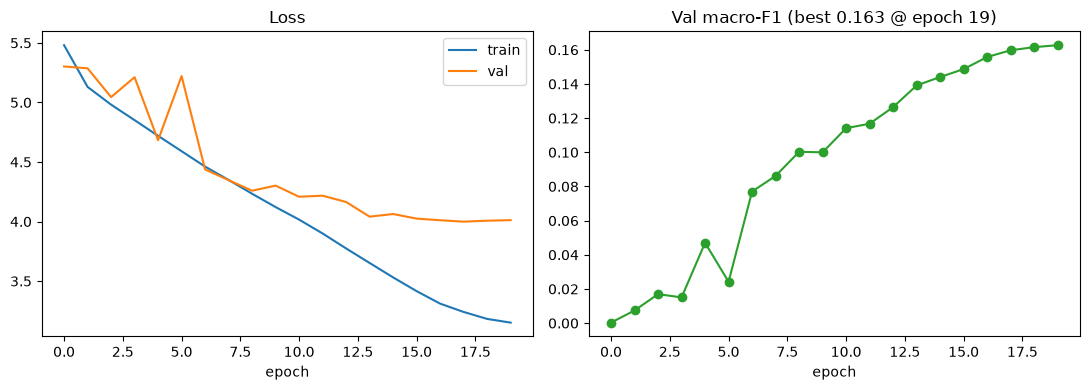

In [66]:
tf.keras.backend.clear_session()
pmoe_model = build_pmoe(SIZE, len(classes), pmoe_backbone, n_experts=N_EXPERTS, l=L_PATCHES, augmentation=AUG, hidden=128,
                        lr=LR_SCHEDULE, weight_decay=WEIGHT_DECAY)
hist_pmoe = run(pmoe_model, f'pmoe_{RUN_TAG}')

top_idx (64, 8, 16) = (images, experts, l patches);  patch grid (8, 8)
gate values of expert 0 on image 0: [0.131 0.119 0.083 0.079 0.064 0.064 0.057 0.057 0.056 0.051 0.046 0.045
 0.042 0.039 0.035 0.03 ]  (they sum to 1.0 )


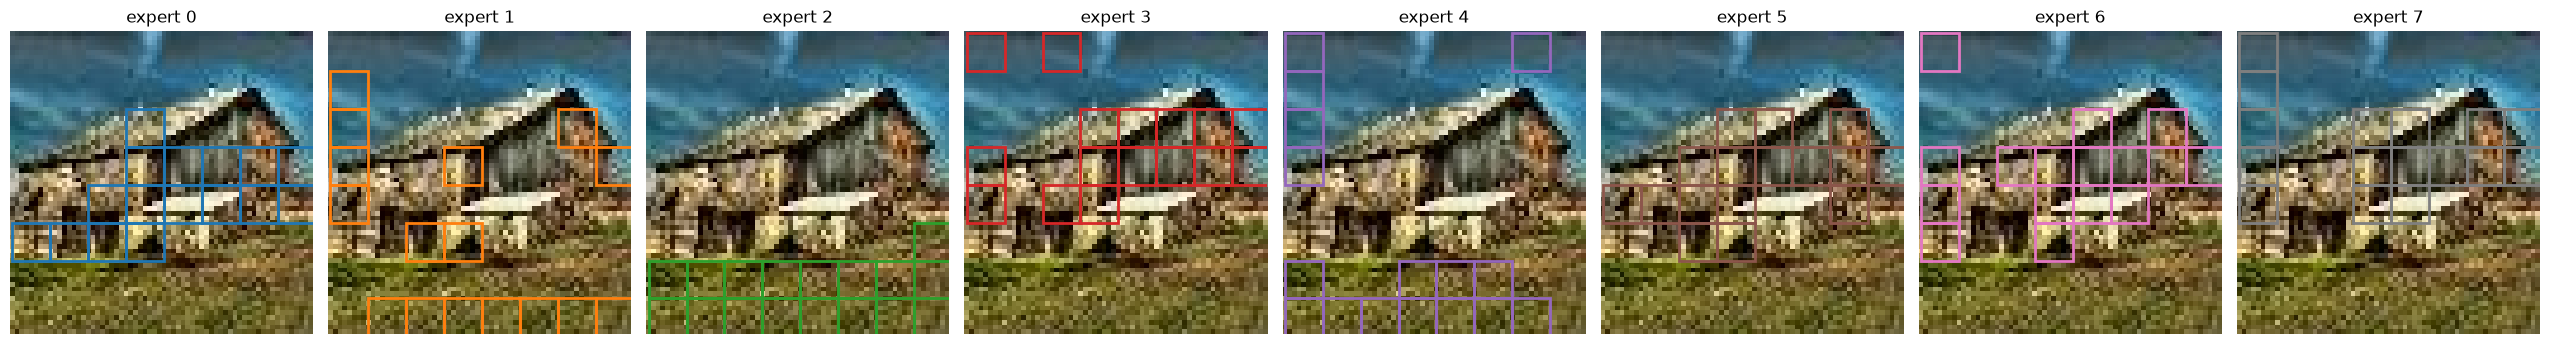

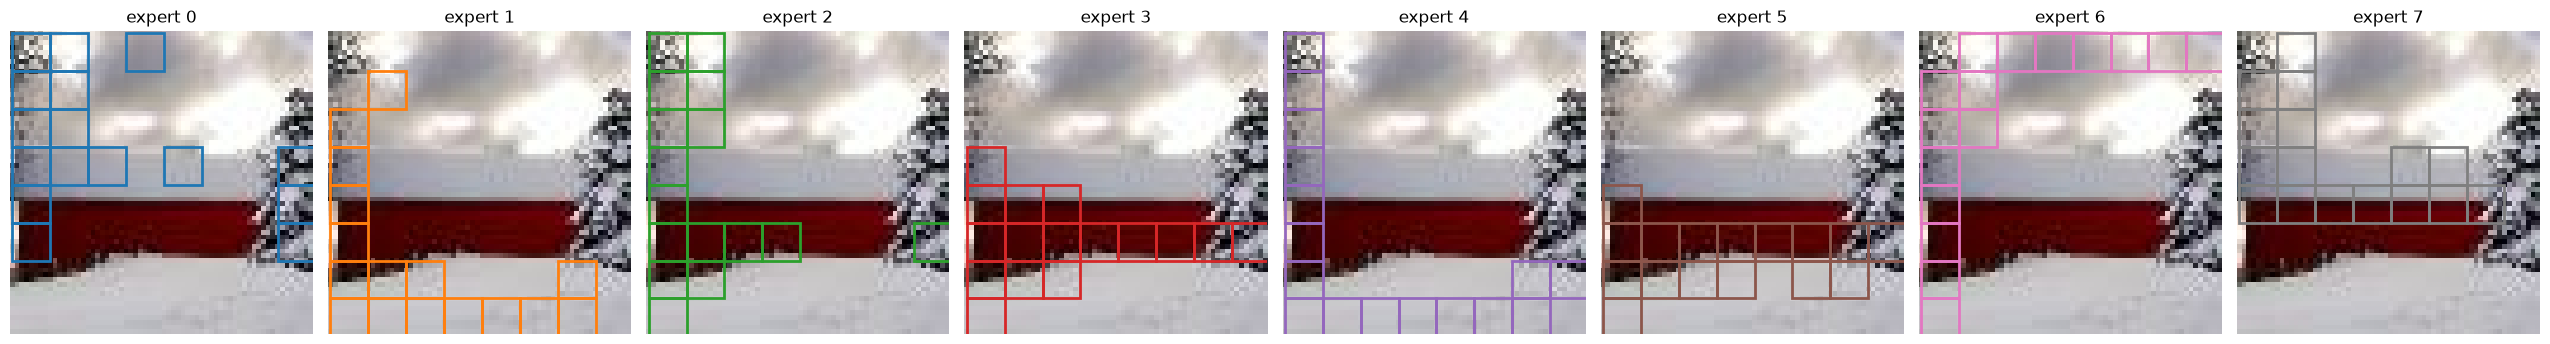

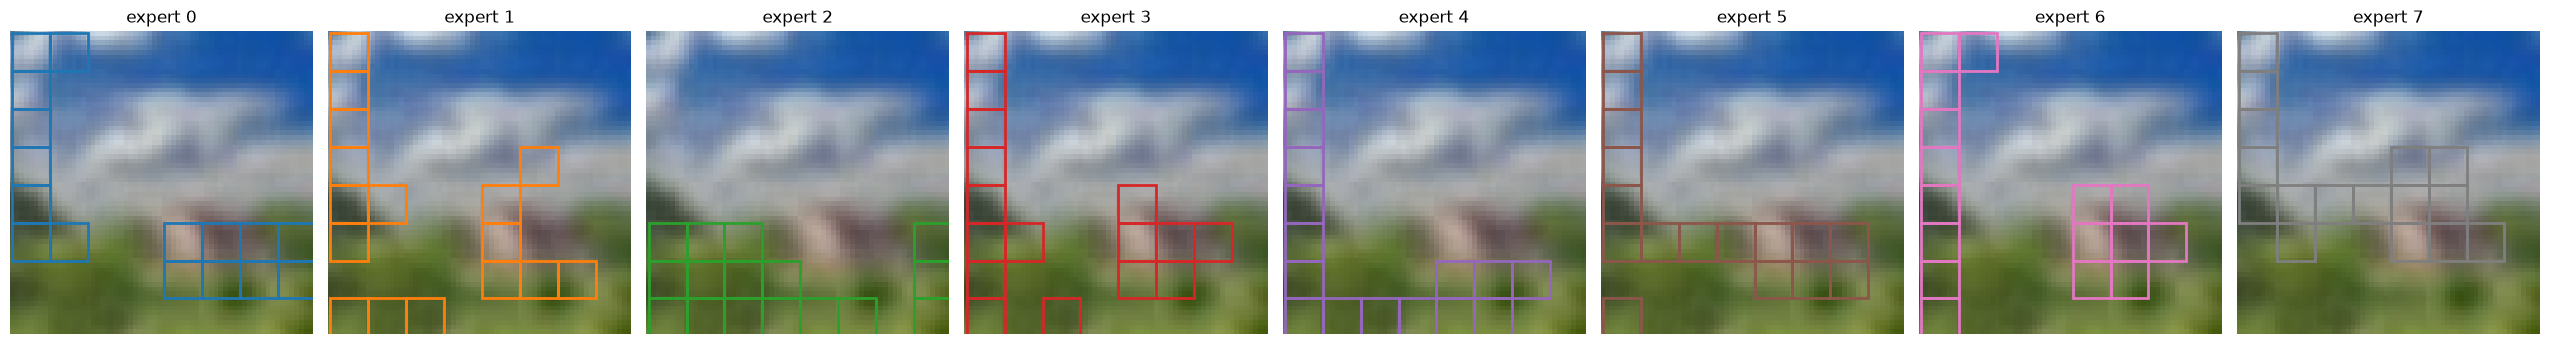

In [67]:
# which patches does each expert pick? one row per image, one panel per expert
images, labels = next(iter(val))
top_idx, gates, grid = expert_choices(pmoe_model, images[:64])
print('top_idx', top_idx.shape, '= (images, experts, l patches);  patch grid', grid)
print('gate values of expert 0 on image 0:', gates[0, 0].round(3), ' (they sum to', gates[0, 0].sum().round(3), ')')

for i in range(3):
    plotting.show_expert_patches(images[i].numpy(), top_idx[i], grid)

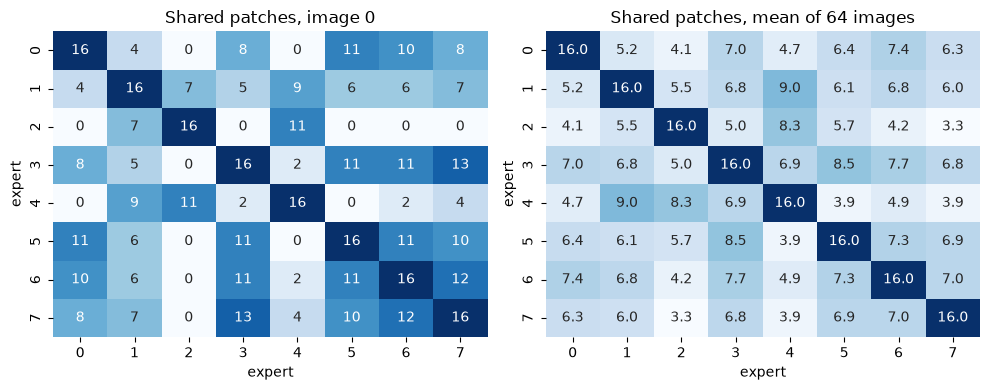

In [68]:
# do the experts pick different patches? number of patches two experts share (the diagonal is l)
# big off-diagonal numbers = the routers did not specialise (pMoE has no balancing loss)
k = top_idx.shape[1]
def overlap(n):
    return np.array([[len(set(top_idx[n, a]) & set(top_idx[n, b])) for b in range(k)] for a in range(k)])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(overlap(0), annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0])
ax[0].set(title='Shared patches, image 0', xlabel='expert', ylabel='expert')
sns.heatmap(np.mean([overlap(n) for n in range(len(top_idx))], axis=0), annot=True, fmt='.1f', cmap='Blues', cbar=False, ax=ax[1])
ax[1].set(title=f'Shared patches, mean of {len(top_idx)} images', xlabel='expert', ylabel='expert')
plt.tight_layout(); plt.show()

## 4. MGE (multi-depth experts)
Adapted from Zhang et al., ICCV 2019. One expert per backbone depth, each with its own loss:
```
s1 (32x32x64)   s2 (16x16x128)   s3 (8x8x256)
      |               |               |
   average                 average                  average          (each expert averages its own map)
   dropout                 dropout                  dropout
   Dense(200)         Dense(200)            Dense(200)
   expert_0              expert_1                expert_2
        \_____________|_______________/
              ensemble = mean of the three  (only used to measure the combination)
```
* A **diversity penalty** (weight `DIVERSITY_WEIGHT`) pushes the experts towards different predictions.
* All three expert losses train the shared backbone; the ensemble only measures the combination.
* The loss Keras prints is the sum of four cross-entropies plus the penalty, so it is **not comparable** with the loss of the other models. Compare accuracy and macro-F1.

Epoch 1/20


I0000 00:00:1795198707.661580 3218845 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1911271__.222


150/151 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - ensemble_accuracy: 0.0197 - ensemble_loss: 5.1781 - expert_0_accuracy: 0.0168 - expert_0_loss: 5.2197 - expert_1_accuracy: 0.0161 - expert_1_loss: 5.2472 - expert_2_accuracy: 0.0148 - expert_2_loss: 5.2591 - loss: 20.9715

I0000 00:00:1795198724.519126 3218849 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_1911271__.222


151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - ensemble_accuracy: 0.0198 - ensemble_loss: 5.1767 - expert_0_accuracy: 0.0169 - expert_0_loss: 5.2183 - expert_1_accuracy: 0.0162 - expert_1_loss: 5.2457 - expert_2_accuracy: 0.0148 - expert_2_loss: 5.2576 - loss: 20.9670  val macro-F1 0.0030
151/151 ━━━━━━━━━━━━━━━━━━━━ 36s 161ms/step - ensemble_accuracy: 0.0198 - ensemble_loss: 5.1767 - expert_0_accuracy: 0.0169 - expert_0_loss: 5.2183 - expert_1_accuracy: 0.0162 - expert_1_loss: 5.2457 - expert_2_accuracy: 0.0148 - expert_2_loss: 5.2576 - loss: 20.9670 - val_ensemble_accuracy: 0.0129 - val_ensemble_loss: 5.4710 - val_expert_0_accuracy: 0.0097 - val_expert_0_loss: 5.2350 - val_expert_1_accuracy: 0.0122 - val_expert_1_loss: 5.6056 - val_expert_2_accuracy: 0.0102 - val_expert_2_loss: 6.0207 - val_loss: 22.4042 - val_f1: 0.0030
Epoch 2/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - ensemble_accuracy: 0.0385 - ensemble_loss: 4.8919 - expert_0_accuracy: 0.0378 - expert_0_loss: 4.9174 - expert_1

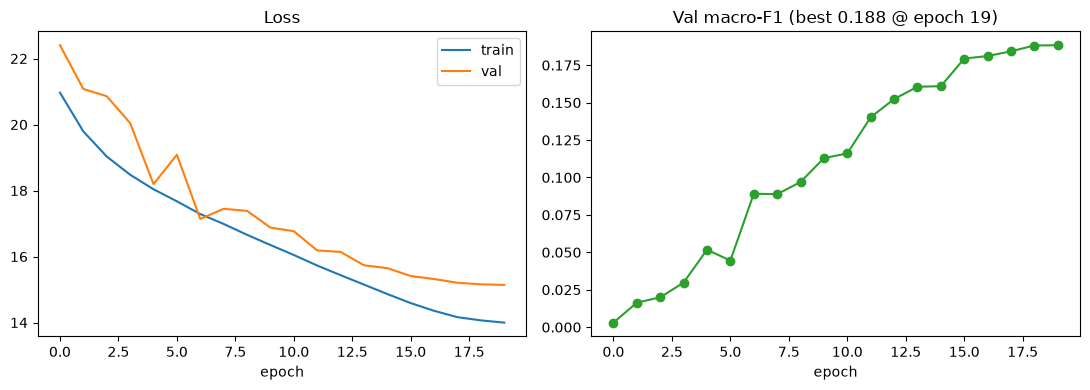

In [69]:
tf.keras.backend.clear_session()
mge_model = build_mge(SIZE, len(classes), fresh_backbone, diversity_weight=DIVERSITY_WEIGHT, augmentation=AUG,
                      lr=LR_SCHEDULE, weight_decay=WEIGHT_DECAY)
hist_mge = run(mge_model, f'mge_{RUN_TAG}')

How good is each MGE expert on its own, and what does averaging them give?

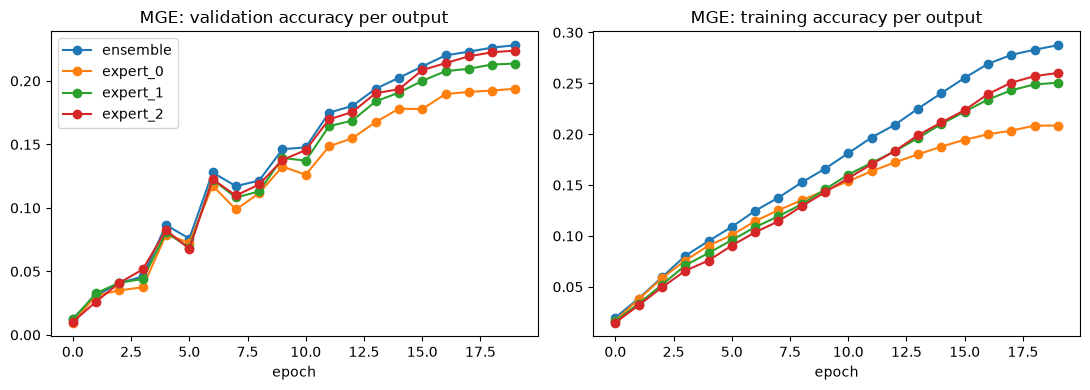

best val accuracy: {'ensemble': 0.2281, 'expert_0': 0.1938, 'expert_1': 0.2137, 'expert_2': 0.2239}


In [70]:
# what does each expert achieve on its own?
h = hist_mge.history
outputs = ['ensemble', 'expert_0', 'expert_1', 'expert_2']

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name in outputs:
    ax[0].plot(h[f'val_{name}_accuracy'], marker='o', label=name)
    ax[1].plot(h[f'{name}_accuracy'], marker='o', label=name)
ax[0].set(title='MGE: validation accuracy per output', xlabel='epoch')
ax[1].set(title='MGE: training accuracy per output', xlabel='epoch')
ax[0].legend(); plt.tight_layout(); plt.show()
print('best val accuracy:', {n: round(max(h[f'val_{n}_accuracy']), 4) for n in outputs})

## Comparison
Loss (solid = validation, dashed = training), validation macro-F1 and validation accuracy of all four models. For MGE the *ensemble* output is used. Macro-F1 gives each of the 200 classes the same weight, so it is the stricter number.

The table after the plots scores every model trained in this session (or loaded with `USE_SAVED`) once more on train and val **with dropout off**, using the weights it ended with (the epoch with the best val loss).

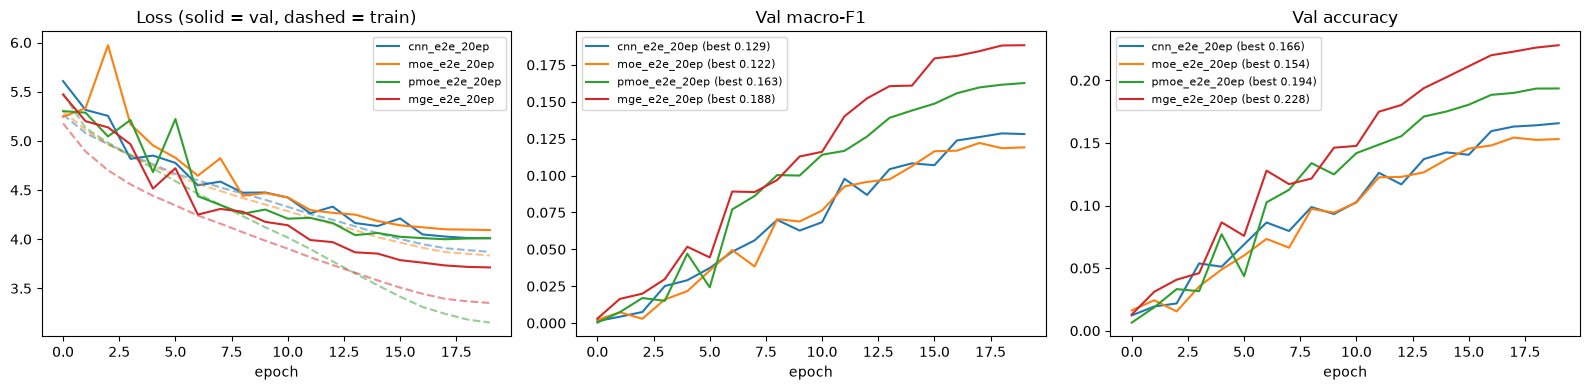

final scores (e2e_20ep, dropout off, train = the oversampled train set):
        params  epochs_run  best_f1_epoch  log_best_val_f1  train_acc  train_f1  val_acc  val_f1  gap_acc
model                                                                                                    
cnn    2067624          20             19           0.1286     0.2169    0.1913   0.1658  0.1281   0.0512
moe    2071080          20             18           0.1221     0.2104    0.1886   0.1527  0.1188   0.0577
pmoe   2071072          20             20           0.1627     0.3850    0.3756   0.1899  0.1596   0.1951
mge    1871416          20             20           0.1883     0.3170    0.2983   0.2281  0.1883   0.0889


In [71]:
# the logs of the four models (a model that was not trained in this session is read from its log)
names = ['cnn', 'moe', 'pmoe', 'mge']
runs = {m: f'{m}_{RUN_TAG}' for m in names}
logs = {m: pd.read_csv(os.path.join(HISTORY_DIR, f'{r}.csv')) for m, r in runs.items()
        if os.path.exists(os.path.join(HISTORY_DIR, f'{r}.csv'))}
plotting.plot_comparison({runs[m]: log for m, log in logs.items()})

# final scores with dropout off: predictions and labels are collected batch by batch, so they stay aligned on the shuffled train set
nets = {'cnn': globals().get('cnn'), 'moe': globals().get('moe_model'), 'pmoe': globals().get('pmoe_model'), 'mge': globals().get('mge_model')}
rows = []
for name, h in logs.items():
    net = nets[name]
    row = dict(model=name, params=net.count_params() if net is not None else None, epochs_run=len(h),
               best_f1_epoch=int(h['val_f1'].values.argmax()) + 1, log_best_val_f1=h['val_f1'].max())
    if net is not None:
        for split, ds in (('train', train), ('val', val)):
            y_true, y_pred = [], []
            for x, y in ds:
                p = net(x, training=False)
                y_pred.append(np.argmax(p[0] if isinstance(p, (list, tuple)) else p, axis=1))   # MGE: the ensemble
                y_true.append(y.numpy())
            y_true, y_pred = np.concatenate(y_true), np.concatenate(y_pred)
            row[f'{split}_acc'] = (y_true == y_pred).mean()
            row[f'{split}_f1'] = f1_score(y_true, y_pred, average='macro')
        row['gap_acc'] = row['train_acc'] - row['val_acc']
    rows.append(row)
final = pd.DataFrame(rows).set_index('model')
print(f'final scores ({RUN_TAG}, dropout off, train = the oversampled train set):')
print(final.round(4).to_string())

How to read the table: `train_*` and `val_*` are measured with dropout off on the weights each model ended with, so `gap_acc` (train minus val accuracy) is real overfitting. The train set is the **oversampled** one (minority classes repeated), so its scores lean on images the model has seen several times. `log_best_val_f1` is the best val macro-F1 of any epoch in the log; the kept weights are the epoch with the best val **loss**, which is not always the same epoch.

### Results
Run `e2e_20ep`: 20 epochs, train set oversampled to 193 images per class (38,600 images), no augmentation, pMoE with `SpatialDropout2D(FEATURE_DROP)` on `s3`. All four models ran the full 20 epochs (early stopping did not trigger) and have about the same number of parameters.

| model | train acc | val acc | val F1 | gap (train - val acc) |
|---|---|---|---|---|
| CNN | 0.217 | 0.166 | 0.128 | 0.051 |
| MoE | 0.210 | 0.153 | 0.119 | 0.058 |
| **pMoE** | **0.385** | 0.190 | 0.160 | **0.195** |
| MGE | 0.317 | **0.228** | **0.188** | 0.089 |

* **MGE** has the best validation scores. Part of that likely comes from deep supervision: its experts on `s1` and `s2` give the early backbone layers their own training signal, which the other models do not have.
* **pMoE** comes second on validation, clearly ahead of CNN and MoE, and fits the training data far better than any other model (38.5% train accuracy). It also has by far the largest train/val gap: it **overfits**, even with feature dropout on `s3`.
* **CNN and MoE** perform about the same. The soft mixture adds nothing over a plain dense head of the same size.

### Conclusion
**pMoE has the most potential of the four heads, as long as its overfitting is controlled.** It already beats the CNN baseline and the plain MoE on validation, and its training accuracy shows a capacity none of the other heads reach. That capacity is not yet turned into validation performance. Patch routing gives pMoE much more freedom than the average pooling the CNN and MoE heads use: each router can pick patches specific to an image, and the backbone adapts to the patches it picks. Feature dropout alone did not close the gap. How far pMoE improves once overfitting is controlled (augmentation, more patches per expert, stronger dropout inside the experts, model selection on val F1) is analysed in depth in the next notebook.